# 02 - Protocole de validation

Objectif : fixer, avant tout modèle, la façon dont on mesure un score. Tous les résultats des étapes suivantes
seront calculés avec le découpage construit ici, sauvegardé dans `artifacts/`.

Prérequis : `utils.py` à la racine du projet, `lightgbm` installé (`pip install lightgbm`).
La section 4 entraîne 25 LightGBM, compter quelques minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import KFold

import utils
from utils import RET, SV, accuracy, compare

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, ORANGE, GREY = '#2a6fdb', '#d9822b', '#8a8f98'

X, y, Xt = utils.load_data()
up = y > 0
X.shape, Xt.shape

((527073, 44), (31870, 44))

## 1. Remettre le train dans l'ordre

Même méthode qu'en EDA (section 6), rangée dans `utils.reconstruct_chronology`. On ne garde un lien a -> b que s'il est
réciproque : b est le meilleur lendemain de a, et a est la meilleure veille de b. Seul le train est utilisé, le test n'a de toute façon aucune voisine.

In [2]:
chrono = utils.reconstruct_chronology(X)
print('taille des chaînes :', chrono.chain.value_counts().head(6).to_dict(), '| nombre de chaînes :', chrono.chain.nunique())
print('score des liens (quantiles 1 %, 5 %, 50 %) :', chrono.link_score.quantile([.01, .05, .5]).round(3).to_dict())

# contrôle indépendant : le jour où SIGNED_VOLUME_1 est renseigné doit revenir toutes les 5 dates
sv1_day = X.SIGNED_VOLUME_1.notna().groupby(X.TS).mean() > .5
c = chrono.join(sv1_day.rename('sv1')).sort_values(['chain', 'pos'])
gaps = c[c.sv1].groupby('chain').pos.diff().dropna()
print('écart entre deux jours SV_1 consécutifs :', gaps.value_counts().head(6).to_dict())

# sens du temps : l'univers grandit le long de la chaîne principale (des allocations sont ajoutées au fil des années)
univ = X.groupby('TS').size()
c0 = chrono[chrono.chain == 0].join(univ.rename('univ')).sort_values('pos')
print('univers médian par quart de la chaîne 0 :', c0.groupby(pd.qcut(c0.pos, 4, labels=False)).univ.median().tolist())

taille des chaînes : {0: 1780, 1: 348, 2: 256, 3: 130, 4: 1, 5: 1} | nombre de chaînes : 12
score des liens (quantiles 1 %, 5 %, 50 %) : {0.01: 0.778, 0.05: 0.911, 0.5: 0.983}
écart entre deux jours SV_1 consécutifs : {5.0: 458, 4.0: 24, 9.0: 7, 8.0: 2, 7.0: 2, 2.0: 1}
univers médian par quart de la chaîne 0 : [65.0, 204.0, 276.0, 276.0]


Le train se range en 4 chaînes (1 780, 348, 256 et 130 dates) plus 8 dates isolées. 95 % des liens ont un score au-dessus de 0,91.

Deux contrôles indépendants du calcul confirment la reconstruction :
- le jour où `SIGNED_VOLUME_1` est renseigné revient toutes les 5 dates dans 92 % des cas, les autres écarts (4, 8, 9) correspondent
  à un jour manquant, typiquement un jour férié ;
- le long de la chaîne principale, l'univers passe de 65 à 276 allocations. Des allocations sont ajoutées avec le temps,
  ce qui confirme que `pos` croissant veut bien dire « plus tard ».

L'ordre relatif des 4 chaînes reste inconnu.

## 2. Le signal au fil du temps

On découpe la chaîne principale en 10 tranches consécutives et on mesure, dans chacune, la force de l'effet « hier »
avec deux indicateurs qui ne demandent aucun entraînement :
- l'accuracy de la règle « signe de `RET_1` » ;
- l'autocorrélation à l'intérieur des fenêtres, qu'on peut aussi calculer sur le test puisqu'elle n'utilise pas la cible.

         univers  acc signe RET_1  corr(target, RET_1)  autocorr intra-fenêtre
tranche                                                                       
0           65.0           0.5384               0.0999                  0.0618
1          204.0           0.5473               0.1216                  0.0751
2          206.0           0.5327               0.1431                  0.0566
3          206.0           0.5160               0.0671                  0.0294
4          276.0           0.5179               0.0289                  0.0380
5          276.0           0.5169               0.0401                  0.0328
6          276.0           0.5082               0.0351                  0.0145
7          276.0           0.5156               0.1004                  0.0539
8          276.0           0.5031              -0.0237                 -0.0389
9          276.0           0.5183               0.0941                  0.0599

autocorr intra-fenêtre du test : 0.0324


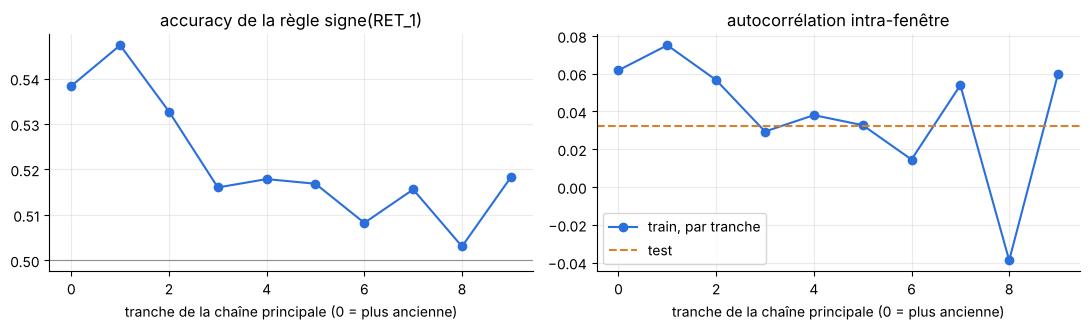

In [3]:
def window_autocorr(df):
    return np.mean([df[f'RET_{k}'].corr(df[f'RET_{k+1}']) for k in range(1, 20)])

d = X.join(chrono, on='TS')
d['hit_r1'] = (d.RET_1 > 0) == up
main = d[d.chain == 0].copy()
main['tranche'] = pd.qcut(main.pos, 10, labels=False)

seg = main.groupby('tranche').apply(lambda g: pd.Series({
    'univers': g.groupby('TS').size().median(),
    'acc signe RET_1': g.hit_r1.mean(),
    'corr(target, RET_1)': y[g.index].corr(g.RET_1),
    'autocorr intra-fenêtre': window_autocorr(g)}), include_groups=False)
ac_test = window_autocorr(Xt)
print(seg.round(4))
print(f"\nautocorr intra-fenêtre du test : {ac_test:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(seg.index, seg['acc signe RET_1'], 'o-', color=BLUE)
ax[0].axhline(.5, color=GREY, lw=.8)
ax[0].set_title('accuracy de la règle signe(RET_1)')
ax[0].set_xlabel('tranche de la chaîne principale (0 = plus ancienne)')
ax[1].plot(seg.index, seg['autocorr intra-fenêtre'], 'o-', color=BLUE, label='train, par tranche')
ax[1].axhline(ac_test, color=ORANGE, lw=1.5, ls='--', label='test')
ax[1].set_title('autocorrélation intra-fenêtre')
ax[1].set_xlabel('tranche de la chaîne principale (0 = plus ancienne)')
ax[1].legend()
plt.tight_layout()
plt.show()

C'est le résultat le plus important de cette étape : **le signal s'affaiblit avec le temps.**
Sur les trois tranches les plus anciennes, la règle naïve fait entre 53,3 % et 54,7 %. Sur les six dernières, elle
reste entre 50,3 % et 51,8 %. L'autocorrélation baisse aussi, de façon plus bruitée : 0,06 à 0,075 au début, entre -0,04 et
0,06 ensuite. Celle du test (0,032) tombe dans la fourchette récente. Le test a aussi 278 allocations par date, comme la fin de la chaîne.

Le test ressemble donc à la période récente, pas à la moyenne de l'historique. Une validation qui mélange toutes les
périodes mesure surtout l'ancien régime, où le signal était fort. C'est l'explication la plus simple de l'écart du
benchmark entre sa CV (52,2 %) et le public (50,79 %).

On définit le **régime récent** comme les dates dont l'univers (médiane glissante sur 21 dates) atteint 270 allocations.

In [4]:
recent = utils.recent_regime(X, chrono)
d['recent'] = d.TS.map(recent)
print(f"dates récentes : {recent.sum()} sur {len(recent)}")
print('part de dates récentes par chaîne :', recent.groupby(chrono.chain).mean().head(4).round(2).to_dict())

pd.DataFrame({name: {'dates': g.TS.nunique(), 'univers médian': g.groupby('TS').size().median(),
                     'base rate': up[g.index].mean(), 'acc signe RET_1': g.hit_r1.mean(),
                     'autocorr intra-fenêtre': window_autocorr(g)}
              for name, g in [('ancien', d[~d.recent]), ('récent', d[d.recent])]}).round(4)

dates récentes : 1493 sur 2522
part de dates récentes par chaîne : {0: 0.43, 1: 0.99, 2: 1.0, 3: 0.93}


,ancien,récent
dates,1029.0000,1493.0000
univers médian,135.0000,276.0000
base rate,0.5078,0.5070
acc signe RET_1,0.5316,0.5145
autocorr intra-fenêtre,0.0595,0.0434


## 3. Le découpage

- **Coffre-fort** : les 250 dernières dates de la chaîne principale, donc les plus récentes dont on est sûr.
  Les 20 dates qui les précèdent sont écartées pour qu'aucune fenêtre ne chevauche le coffre-fort.
  On ne le regardera qu'une fois, à la fin, avec le modèle final.
- **Développement** : le reste, coupé en blocs de 60 dates consécutives. Les blocs sont répartis au hasard entre 8 plis,
  séparément pour les blocs récents et anciens, pour que chaque pli contienne des dates récentes.
- **Purge** : pour chaque pli, on retire de l'entraînement les dates à moins de 20 positions d'une date de validation
  de la même chaîne. 20 = la longueur d'une fenêtre.

In [5]:
ch, folds = utils.make_split(chrono, recent=recent)
print(ch.set.value_counts().to_dict())

summary = pd.DataFrame([{'pli': k, 'dates train': len(f['train']), 'dates val': len(f['val']),
                         'dont récentes': int(recent[list(f['val'])].sum()), 'dates purgées': len(f['purged'])}
                        for k, f in enumerate(folds)]).set_index('pli')
print(summary)

# vérification : aucune date d'entraînement à moins de 21 positions d'une date de validation de la même chaîne
for f in folds:
    v = ch.loc[list(f['val']), ['chain', 'pos']]
    t = ch.loc[list(f['train']), ['chain', 'pos']]
    m = v.merge(t, on='chain')
    assert ((m.pos_x - m.pos_y).abs() > utils.WINDOW).all()
    assert not (f['train'] & set(ch.index[ch.set != 'dev']))
print('purge vérifiée, coffre-fort absent de tous les plis')

utils.save_split(ch, folds)

{'dev': 2252, 'lockbox': 250, 'purged': 20}
     dates train  dates val  dont récentes  dates purgées
pli                                                      
0           1785        301            171            166
1           1791        301            180            160
2           1652        360            180            240
3           1905        207             86            140
4           1692        360            178            200
5           1692        360            194            200
6           1960        192            129            100
7           1981        171            105            100
purge vérifiée, coffre-fort absent de tous les plis


## 4. Ce que le protocole change : le benchmark LightGBM

On reprend exactement les features et le LightGBM du notebook de QRT, et on le note de trois façons, toujours sur les
dates de développement :
- **A** : son KFold d'origine (dates tirées au hasard) ;
- **B** : nos blocs, sans purge ;
- **C** : nos blocs, avec purge (le protocole retenu).

Pour chaque schéma, on calcule l'accuracy sur toutes les dates de validation et sur les seules dates récentes.

In [6]:
def benchmark_features(df):
    df = df.copy()
    for i in [3, 5, 10, 15, 20]:
        df[f'AVERAGE_PERF_{i}'] = df[RET[:i]].mean(axis=1)
        df[f'ALLOCATIONS_AVERAGE_PERF_{i}'] = df.groupby('TS')[f'AVERAGE_PERF_{i}'].transform('mean')
    df['STD_PERF_20'] = df[RET].std(axis=1)
    df['ALLOCATIONS_STD_PERF_20'] = df.groupby('TS')['STD_PERF_20'].transform('mean')
    return df

F = benchmark_features(X)
FEATS = (RET + SV + ['MEDIAN_DAILY_TURNOVER']
         + [f'AVERAGE_PERF_{i}' for i in [3, 5, 10, 15, 20]]
         + [f'ALLOCATIONS_AVERAGE_PERF_{i}' for i in [3, 5, 10, 15, 20]]
         + ['STD_PERF_20', 'ALLOCATIONS_STD_PERF_20'])
PARAMS = dict(objective='mse', seed=SEED, verbosity=-1, learning_rate=1e-2, max_depth=3)

def fit_predict(train_dates, val_dates):
    tr = F.TS.isin(train_dates).to_numpy()
    va = F.TS.isin(val_dates).to_numpy()
    model = lgb.train(PARAMS, lgb.Dataset(F.loc[tr, FEATS], label=y[tr].to_numpy()), num_boost_round=500)
    return va, model.predict(F.loc[va, FEATS])

is_recent = d.recent.to_numpy()
dev_dates = np.array(sorted(ch.index[ch.set == 'dev']))

def score_folds(splits):
    out = []
    for train_dates, val_dates in splits:
        va, pred = fit_predict(train_dates, val_dates)
        rv = va & is_recent
        out.append({'toutes': accuracy(y[va], pred), 'récentes': accuracy(y[rv], pred[is_recent[va]])})
    return pd.DataFrame(out)

kf = KFold(8, shuffle=True, random_state=0)
splits = {
    'A KFold mélangé': [(set(dev_dates[tr]), set(dev_dates[va])) for tr, va in kf.split(dev_dates)],
    'B blocs sans purge': [(set(dev_dates) - f['val'], f['val']) for f in folds],
    'C blocs purgés': [(f['train'], f['val']) for f in folds],
}
results = {name: score_folds(s) for name, s in splits.items()}

In [7]:
va, pred = fit_predict(set(dev_dates), set(ch.index[ch.set == 'lockbox']))
lockbox_acc = accuracy(y[va], pred)

se = lambda s: s.std(ddof=1) / np.sqrt(len(s))
table = pd.DataFrame({name: {'toutes les dates': r['toutes'].mean(), 'erreur-type': se(r['toutes']),
                             'dates récentes': r['récentes'].mean(), 'erreur-type ': se(r['récentes'])}
                      for name, r in results.items()}).T
print(table.round(4))
print(f"\ncoffre-fort (entraîné sur tout le développement) : {lockbox_acc:.4f}")
print('score public du benchmark (QRT) : 0.5079')

                    toutes les dates  erreur-type  dates récentes  \
A KFold mélangé               0.5223       0.0014          0.5179   
B blocs sans purge            0.5225       0.0017          0.5189   
C blocs purgés                0.5217       0.0015          0.5184   

                    erreur-type   
A KFold mélangé           0.0013  
B blocs sans purge        0.0016  
C blocs purgés            0.0014  

coffre-fort (entraîné sur tout le développement) : 0.5142
score public du benchmark (QRT) : 0.5079


Lecture du tableau :

1. **Le découpage (blocs, purge) ne change rien pour ce modèle.** A, B et C donnent tous ~52,2 % sur l'ensemble des dates,
   avec des erreurs-types comparables. Avec des features calculées ligne par ligne, un LightGBM peu profond n'exploite pas le
   chevauchement des fenêtres. On garde quand même blocs et purge : ils ne coûtent presque rien et deviendront nécessaires dès
   qu'on construira des features à partir de l'historique d'une allocation (target encoding, statistiques glissantes).
2. **Ce qui change le score, c'est la période évaluée.** Sur les dates récentes, on passe à ~51,8 %. Sur le coffre-fort,
   période la plus récente et jamais vue, à 51,4 %. Le public est à 50,79 %. Plus l'évaluation ressemble au test, plus le
   score baisse, et il se rapproche du public.
3. **Même la métrique récente reste un peu optimiste** (51,8 % contre 51,4 % sur le coffre-fort). Dans un pli, le modèle
   s'entraîne sur des périodes situées avant et après le bloc de validation, alors que sur le test il doit extrapoler
   vers une période plus tardive. Il faudra garder en tête une décote de l'ordre de 0,5 point entre la CV récente et le public.

Conclusion : l'optimisme de la CV du benchmark ne vient pas d'une fuite d'information. Il vient de la **non-stationnarité**
du signal. La métrique qu'on suivra est donc l'accuracy sur les dates récentes.

## 5. Protocole retenu et règle de décision

- Découpage : les 8 plis purgés ci-dessus, sauvegardés dans `artifacts/`. Tous les notebooks suivants les rechargent avec `utils.load_split()`.
- Métrique principale : accuracy sur les dates récentes de validation (moyenne sur les 8 plis). On affiche aussi toutes les dates.
- Entraînement : sur toutes les dates d'entraînement du pli, anciennes comprises. Pondérer ou écarter l'ancien régime
  sera une idée à tester à l'étape d, pas une hypothèse de départ.
- Règle de décision : une idée est retenue si elle bat la référence sur les mêmes plis avec un gain moyen supérieur
  à deux erreurs-types de la différence (`utils.compare`).
- Coffre-fort : évalué une seule fois, avec le modèle final.

Exemple de la règle : le benchmark LightGBM bat-il la règle naïve signe(`RET_1`) sur les dates récentes ?

In [8]:
naive = []
for f in folds:
    m = d.TS.isin(f['val']).to_numpy() & is_recent
    naive.append(d.hit_r1[m].mean())

print('règle naïve, dates récentes, par pli :', np.round(naive, 4))
print('LightGBM C, dates récentes, par pli   :', results['C blocs purgés']['récentes'].round(4).to_numpy())
compare(results['C blocs purgés']['récentes'], naive)

règle naïve, dates récentes, par pli : [0.5183 0.5143 0.5189 0.518  0.5081 0.5159 0.5148 0.517 ]
LightGBM C, dates récentes, par pli   : [0.5243 0.5132 0.5194 0.5205 0.5128 0.5165 0.5209 0.5195]


{'mean_diff': np.float64(0.002729689600347626),
 'se': np.float64(0.0009439979111770024),
 't': np.float64(2.8916267377585347),
 'retenu': True}

Le LightGBM du benchmark bat la règle naïve de 0,27 point sur les dates récentes, avec un t de 2,9 : l'écart est réel
selon notre règle, mais modeste. Ses 52 features n'apportent presque rien au-delà du signe du rendement de la veille.
C'est le point de départ de l'étape c : la référence à battre est basse, et chaque gain devra passer la règle des deux erreurs-types.

## Ce qui pourrait invalider ce protocole

- Une erreur de chaînage rendrait voisins deux blocs supposés séparés. Les contrôles de la section 1 (motif hebdomadaire,
  croissance de l'univers) et la purge limitent ce risque.
- L'ordre entre les 4 chaînes est inconnu. Le coffre-fort est pris à l'intérieur de la chaîne principale, là où le sens du temps est sûr.
- La définition du régime récent (univers ≥ 270) est un indicateur indirect de la date. Si le test venait d'une autre
  période avec un univers complet, la métrique serait moins représentative. Le score public servira de contrôle.
- L'erreur-type de la métrique récente est d'environ 0,15 point. Comparer deux modèles sur les mêmes plis est plus précis
  (0,09 point dans l'exemple ci-dessus), d'où une règle de décision sur les différences pli par pli.
- La CV récente surestime le coffre-fort d'environ 0,4 point (interpolation contre extrapolation). Les gains mesurés en CV
  devront être confirmés sur le public, en gardant en tête que les deux peuvent diverger.
- Chaque idée testée sur ces plis consomme un peu de leur fiabilité. On tient un journal des essais et le coffre-fort mesure l'excès à la fin.